<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/50_vinculos/53_prediccion_regional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 53 · Predicción regional del cambio agropecuario

**Autor:** Jonatan

**Pregunta:** ¿la lluvia y la quema del año anterior mejoran el pronóstico a un año del cambio agropecuario regional frente a un ARIMA de referencia?

**Entradas:**
- `datos/comunes/`: `firms_mensual_municipio.csv` (cuaderno 03), `chirps_mensual_municipio.csv` (cuaderno 11) y `oni_mensual.csv` (cuaderno 10).
- `modulos/expansion/datos/procesados/` (DVC): coberturas MapBiomas y EVA, de los scripts `02_unir_mapbiomas.py` y `03_series_y_cruce_eva.py` del módulo de expansión.
- `modulos/fuego_expansion/datos/crudos/` (DVC): área quemada de MapBiomas Fuego y pérdida de vegetación.
- El panel municipio × año se construye en el cuaderno con `scripts/01_preparar_panel.py`, así que no depende de otro cuaderno.

**Salidas:**
- `modulos/fuego_expansion/resultados/tablas/municipal/prediccion_regional_anual.csv` y `prediccion_regional_mae.csv`.

**Método:** pronóstico ingenuo (el último valor observado), ARIMA de referencia, ARIMAX con lluvia y ARIMAX con lluvia y quema, evaluados fuera de muestra con origen rodante. Se reportan el MAE y el MASE; la comparación entre los dos ARIMAX mide el aporte predictivo de la quema.

## Predicción regional del cambio agropecuario

Comparamos un **ARIMA de referencia**, un **ARIMAX con lluvia** y un **ARIMAX con lluvia y quema** para pronosticar a un año el cambio neto agropecuario de la Altillanura. La comparación entre los dos ARIMAX mide el aporte predictivo adicional de la quema. La unidad es el **año regional**. La serie regional agrega los siete municipios antes de calcular las proporciones y se construye aquí mismo con `scripts/01_preparar_panel.py`. `statsmodels` está en el `requirements.txt` de la raíz.

## 1. Resultado, predictores y fecha de corte

- **Resultado principal (`d_agro_pct`).** Cambio neto de hectáreas agropecuarias entre $t-1$ y $t$, dividido por el área total regional de $t-1$ y multiplicado por 100. Se expresa en puntos porcentuales (pp) del territorio previo.
- **Resultado complementario (`crec_agro_pct`).** El mismo saldo dividido por el área agropecuaria regional de $t-1$ y multiplicado por 100. Cada pronóstico principal se multiplica por el cociente entre el territorio y el área agropecuaria de $t-1$. Las dos escalas representan la misma ganancia o pérdida en hectáreas.
- **Lluvia seca regional de $t-1$.** Precipitación CHIRPS acumulada de diciembre de $t-2$ a marzo de $t-1$, promediada entre municipios con ponderación por área.
- **Tasa regional de quema natural de $t-1$.** Hectáreas quemadas de formación natural no forestal en el año calendario $t-1$, divididas por las hectáreas regionales de esa cobertura y multiplicadas por 100.

> **Observación sobre la disponibilidad histórica de los datos.** El pronóstico para $t$ supone un corte al cierre de $t-1$. Este cuaderno no verifica, por insumo y año, la fecha de publicación ni qué versión de los datos se podía consultar entonces. Esto aplica a CHIRPS, a la quema anual de MapBiomas y a la cobertura agropecuaria que alimenta la historia del resultado y los denominadores. Por ejemplo, para pronosticar 2020 se supone que las capas de cobertura y quema de 2019 se podían usar al cierre de 2019. Si algún dato se publicó después, el pronóstico en tiempo real habría tenido menos información que esta evaluación. Las cifras de este notebook provienen de una simulación retrospectiva con la serie consolidada actual y están condicionadas a ese supuesto de disponibilidad.

In [1]:
import sys
import warnings
from importlib import import_module

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA

# Rutas del proyecto: funcionan en Colab y en local
import os, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/

def traer(ruta):
    """Baja de DVC una carpeta o un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

traer('modulos/fuego_expansion/datos/crudos')
traer('modulos/expansion/datos/procesados')
sys.path.insert(0, os.path.join(RAIZ, 'modulos', 'fuego_expansion', 'scripts'))

import config as cfg

preparar = import_module("01_preparar_panel")
regional = preparar.serie_regional(preparar.construir_panel()).set_index("anio").sort_index()
if not np.array_equal(regional.index, np.arange(regional.index.min(), regional.index.max() + 1)):
    raise ValueError("Se requiere una observación por año y un calendario consecutivo.")

objetivo = "d_agro_pct"
complementario = "crec_agro_pct"
lluvia = "lluvia_seca_mm_rez1"
quema = "tasa_quema_natural_rez1"
areas = ["area_total_ha_rez1", "agro_ha_rez1"]
datos = regional[[objetivo, complementario, *areas]].assign(
    **{lluvia: regional["lluvia_seca_mm"].shift(),
       quema: regional["tasa_quema_natural"].shift()}
).iloc[1:].copy()
if not np.isfinite(datos.to_numpy()).all() or (datos[areas] <= 0).any().any():
    raise ValueError("La ventana común requiere datos completos y áreas previas positivas.")
datos["factor_agro_previo"] = datos[areas[0]] / datos[areas[1]]
np.testing.assert_allclose(datos[objetivo] * datos["factor_agro_previo"], datos[complementario])
display(datos[[objetivo, complementario, lluvia, quema]].head().round(3))

,d_agro_pct,crec_agro_pct,lluvia_seca_mm_rez1,tasa_quema_natural_rez1
anio,,,,
2002,0.043,0.634,310.331,26.863
2003,0.082,1.205,407.762,22.549
2004,0.119,1.732,228.947,27.015
2005,0.362,5.197,281.843,35.182
2006,-0.012,-0.168,342.188,17.256


## 2. Comparación fuera de muestra

La ventana común empieza en **2002**, el primer año con ambos rezagos en la serie regional. El primer entrenamiento usa **2002–2015** y pronostica **2016**. Se amplía el entrenamiento un año en cada paso y se vuelve a pronosticar el siguiente hasta **2024**. Los tres modelos comparten exactamente los mismos años de entrenamiento y evaluación.

En cada corte se selecciona por **AICc del ARIMA base** entre `(0,0,0)`, que pronostica la media, y `(1,0,0)`, que añade dependencia del último cambio anual. Se fija $d=0$ porque el resultado ya mide un cambio anual. Los tres modelos usan el mismo orden seleccionado en ese corte para que la comparación aísle el aporte de los regresores. El resultado y los regresores se estandarizan con las medias y desviaciones del entrenamiento para facilitar el ajuste numérico. El pronóstico se devuelve a sus unidades originales.

La métrica principal es el **error absoluto medio (MAE)** en pp del territorio previo. También se reporta en pp de la tasa de crecimiento agropecuario. En esa escala, un mismo error en hectáreas pesa más cuando la base agropecuaria previa es menor.

El **MASE** compara cada modelo con el pronóstico ingenuo, que repite el último valor observado. En cada corte, el error absoluto del pronóstico se divide por el error absoluto medio que tuvo el ingenuo dentro del entrenamiento de ese corte; el MASE es el promedio de esos cocientes en los nueve años. Un valor menor que 1 indica que el modelo se equivoca menos de lo que se equivocaba el ingenuo en los datos ya conocidos. El ingenuo también se evalúa fuera de muestra, como una fila más de la tabla, para comparar los modelos con él en los mismos años.

In [2]:
modelos = {
    "ARIMA": [],
    "ARIMAX lluvia": [lluvia],
    "ARIMAX lluvia + quema": [lluvia, quema],
}
ordenes = [(0, 0, 0), (1, 0, 0)]
primer_pronostico = 2016
if primer_pronostico not in datos.index or (datos.index < primer_pronostico).sum() < 10:
    raise ValueError("Se necesitan al menos diez años de entrenamiento y un año evaluable.")

def ajustar(y, orden, x=None):
    with warnings.catch_warnings():
        warnings.filterwarnings("error", category=ConvergenceWarning)
        return ARIMA(y, exog=x, order=orden, trend="c").fit()

filas = []
for anio in datos.index[datos.index >= primer_pronostico]:
    entrenamiento = datos.loc[datos.index < anio]
    y = entrenamiento[objetivo].to_numpy()
    centro_y, escala_y = y.mean(), y.std()
    if escala_y == 0:
        raise ValueError(f"El resultado es constante en el entrenamiento para {anio}.")
    y_estandar = (y - centro_y) / escala_y
    base = min((ajustar(y_estandar, orden) for orden in ordenes), key=lambda ajuste: ajuste.aicc)
    orden = base.model.order
    # Escala del MASE: error absoluto medio del pronóstico ingenuo dentro del entrenamiento.
    mae_ingenuo = np.abs(np.diff(y)).mean()
    filas.append({
        "anio": anio, "modelo": "Ingenuo (último valor)", "orden": "", "n_entrenamiento": len(y),
        "observado_pp_territorio": datos.at[anio, objetivo],
        "pronostico_pp_territorio": y[-1],
        "observado_pct_agro_previo": datos.at[anio, complementario],
        "pronostico_pct_agro_previo": y[-1] * datos.at[anio, "factor_agro_previo"],
        "mae_ingenuo_entrenamiento_pp_territorio": mae_ingenuo,
    })
    for nombre, variables in modelos.items():
        if variables:
            x = entrenamiento[variables]
            centro, escala = x.mean(), x.std(ddof=0)
            if (escala == 0).any():
                raise ValueError(f"Hay un predictor constante en el entrenamiento para {anio}.")
            x_entrena = ((x - centro) / escala).to_numpy()
            x_nuevo = ((datos.loc[[anio], variables] - centro) / escala).to_numpy()
            ajuste = ajustar(y_estandar, orden, x_entrena)
            prediccion = ajuste.forecast(steps=1, exog=x_nuevo)[0]
        else:
            prediccion = base.forecast(steps=1)[0]
        pronostico = centro_y + escala_y * prediccion
        filas.append({
            "anio": anio, "modelo": nombre, "orden": str(orden), "n_entrenamiento": len(y),
            "observado_pp_territorio": datos.at[anio, objetivo],
            "pronostico_pp_territorio": pronostico,
            "observado_pct_agro_previo": datos.at[anio, complementario],
            "pronostico_pct_agro_previo": pronostico * datos.at[anio, "factor_agro_previo"],
            "mae_ingenuo_entrenamiento_pp_territorio": mae_ingenuo,
        })

pronosticos = pd.DataFrame(filas)
for escala in ("pp_territorio", "pct_agro_previo"):
    pronosticos[f"error_abs_{escala}"] = (
        pronosticos[f"pronostico_{escala}"] - pronosticos[f"observado_{escala}"]
    ).abs()
pronosticos["error_escalado"] = (
    pronosticos["error_abs_pp_territorio"] / pronosticos["mae_ingenuo_entrenamiento_pp_territorio"]
)
resumen = pronosticos.groupby("modelo", sort=False).agg(
    n_pronosticos=("anio", "size"),
    mae_pp_territorio=("error_abs_pp_territorio", "mean"),
    mae_pp_crecimiento=("error_abs_pct_agro_previo", "mean"),
    mase=("error_escalado", "mean"),
)
display(resumen.round(4))

tablas = cfg.TABLAS / "municipal"
tablas.mkdir(parents=True, exist_ok=True)
pronosticos.to_csv(tablas / "prediccion_regional_anual.csv", index=False, encoding="utf-8-sig")
resumen.to_csv(tablas / "prediccion_regional_mae.csv", encoding="utf-8-sig")

,n_pronosticos,mae_pp_territorio,mae_pp_crecimiento,mase
modelo,,,,
Ingenuo (último valor),9,0.1192,1.0602,0.9901
ARIMA,9,0.0958,0.8557,0.7916
ARIMAX lluvia,9,0.0967,0.8627,0.7988
ARIMAX lluvia + quema,9,0.0892,0.8000,0.7407


## 3. Revisar los pronósticos y los errores por año

La figura compara las trayectorias observadas y pronosticadas en las dos escalas. La tabla muestra el error absoluto en pp del territorio por año. La última columna indica si añadir quema redujo ese error frente a usar solo lluvia. Con nueve años de evaluación, la comparación es descriptiva y un solo año puede tener peso en el MAE.

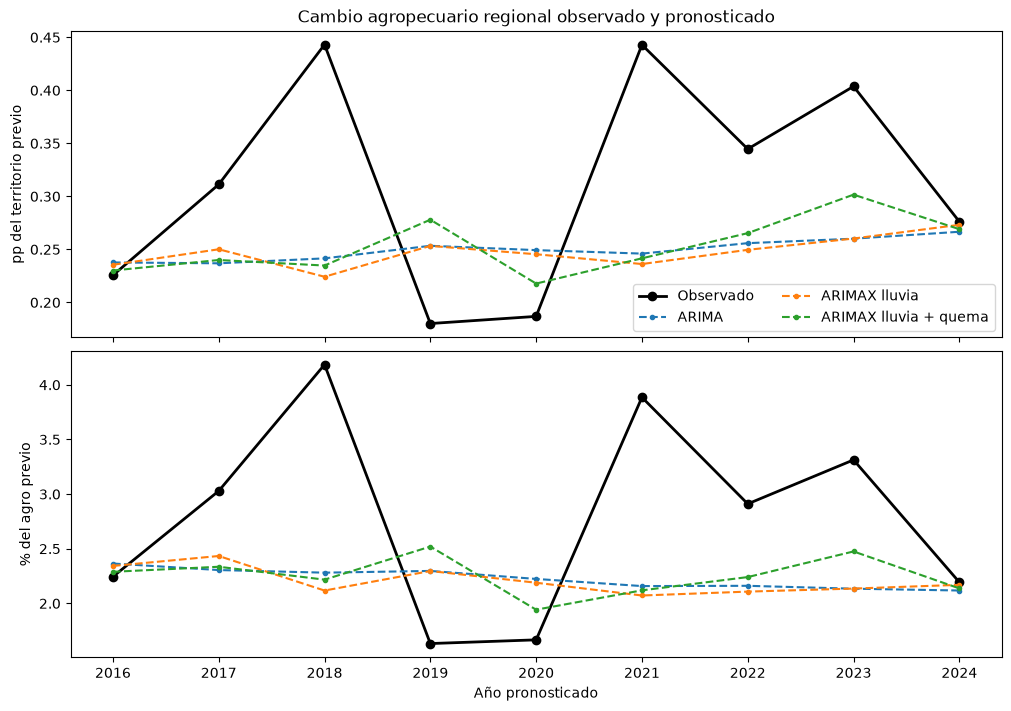

modelo,ARIMA,ARIMAX lluvia,ARIMAX lluvia + quema,Mejora al añadir quema
anio,,,,
2016,0.0121,0.0099,0.0045,True
2017,0.0744,0.0612,0.0713,False
2018,0.2016,0.2189,0.2083,True
2019,0.0733,0.0732,0.0979,False
2020,0.0625,0.0586,0.0309,True
2021,0.1969,0.2067,0.2013,True
2022,0.0888,0.0951,0.0793,True
2023,0.1436,0.1435,0.1021,True
2024,0.0095,0.0030,0.0071,False


In [3]:
fig, ejes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
observado = pronosticos.loc[pronosticos["modelo"].eq("ARIMA")]
for ax, escala, unidad in zip(
    ejes, ("pp_territorio", "pct_agro_previo"), ("pp del territorio previo", "% del agro previo")
):
    ax.plot(observado["anio"], observado[f"observado_{escala}"],
            "o-", color="black", linewidth=2, label="Observado")
    for nombre, grupo in pronosticos[pronosticos["modelo"].isin(modelos)].groupby("modelo", sort=False):
        ax.plot(grupo["anio"], grupo[f"pronostico_{escala}"], "o--",
                markersize=3, label=nombre)
    ax.set(ylabel=unidad)
ejes[0].set(title="Cambio agropecuario regional observado y pronosticado")
ejes[0].legend(ncols=2)
ejes[-1].set(xlabel="Año pronosticado", xticks=observado["anio"])
plt.show()

errores = pronosticos.pivot(index="anio", columns="modelo", values="error_abs_pp_territorio")
errores = errores[list(modelos)]
errores["Mejora al añadir quema"] = errores["ARIMAX lluvia + quema"] < errores["ARIMAX lluvia"]
display(errores.round(4))

## Lectura del ejercicio

Entre 2016 y 2024, los tres modelos le ganan al pronóstico ingenuo: su MASE es menor que 1 (**0,79** el ARIMA, **0,80** el ARIMAX con lluvia y **0,74** el ARIMAX con lluvia y quema), mientras que el ingenuo evaluado en los mismos años queda en **0,99**. El ingenuo tiene además el mayor MAE, **0,1192 pp del territorio**.

El menor error en las dos escalas corresponde al modelo con lluvia y quema. En la escala principal, su MAE es **0,0892 pp del territorio**, frente a **0,0958** para el ARIMA y **0,0967** para el modelo con lluvia. La lluvia sola no mejora la referencia; la quema la mejora cerca de un 7 %. Añadir quema al modelo con lluvia reduce el error absoluto en **6 de 9 años**. Con nueve pronósticos, esa ventaja es descriptiva: no alcanza para afirmar que la quema anticipa el cambio agropecuario. El resultado describe esta ventana de evaluación y está condicionado al supuesto de disponibilidad histórica descrito en la observación inicial.

El AICc seleccionó `(0,0,0)` en los nueve cortes. En esta corrida, la referencia pronostica la media del entrenamiento y los ARIMAX añaden los regresores sin un término autorregresivo.